# Janis Newman Winicour
$f=g^{-1}=(1-b/r)^\gamma$, $h=r^2(1-b/r)^{1-\gamma}$, with $b=2\sqrt{M^2+q_{\rm JNW}^2}$ and $\gamma=2M/b$ (Virbhadra 1997). The hair is $q_{\rm JNW}/M\sim\mathcal U(-600,600)$; $q=0$ is Schwarzschild.

The metric depends on $q^2$, so the sign is not measurable and the deviation grows like $(b/r)^2$, so expect large charge constraints

In [1]:
import sys, copy, warnings, dataclasses
sys.path.insert(0, '..')                      # the package lives one level up
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np, torch
import matplotlib.pyplot as plt
%matplotlib inline

from ginn.core import S2Data, keplerian_prefit, LossConfig, train, objective, fit
from ginn.physics import METRICS
from ginn import analysis as an
from ginn import plotting as pl

data = S2Data.from_csv('../data/tab_gillessen_pos.csv', '../data/tab_gillessen_vr.csv')
print(data.summary())

Gillessen+2017: 145 astrometric epochs, 44 RVs, 1992.22-2016.53;  N_data = 334


In [2]:
N_STEPS_GINN   = 3000        
N_STEPS_KEPLER = 2000        
N_STEPS_EXACT  = 1500        
MODEL = dict(hidden=(32, 32),        
             nn_out_scale=1e-3)      
TRAIN = dict(lr_u=0.1,               
             lr_nn=5e-4,             
             lr_floor=0.01,          
             precondition=(0.0,))    

cfg = LossConfig(eps_phys=1e-4,      
                 n_colloc=256,       
                 sigma_w=10.0)       
FRAME = ['x0', 'y0', 'vx0', 'vy0', 'vz0']
LIT = {'inc': 134.18, 'Omega': 226.94, 'omega': 65.51}  

METRIC    = 'jnw'
HAIR_INIT = {'q_jnw': 20.0}   
FIXED     = ()        
SCAN      = None   
N_STEPS_WARM = 1000        
HOLD_HAIR_IN_ADAM = False  


GN = dict(n_iter=30,       
          n_retrain=400,   
          tol=0.02,        
          lr_nn=2e-3)      
USE_FSP = False            
CORNER = dict(n_samples=200_000,   
              bins=40,             
              smooth=1.5)          
metric = METRICS[METRIC]
if USE_FSP:
    cfg = dataclasses.replace(cfg, external_precession=(1.10, 0.19))
HOLD = tuple(hp.name for hp in metric.hair if hp.name not in FIXED)
for hp in metric.hair: print(hp)

HairParam(name='q_jnw', latex='$q_{\\rm JNW}$', prior=Uniform(-600, 600), init=20.0, scale=5.0, gr_value=0.0)


In [3]:
# from ginn.physics import orbit_constants, M_SUN_GEOM_AU
# M_, a_, e_ = torch.tensor(4.26e6 * M_SUN_GEOM_AU), torch.tensor(1031.2), torch.tensor(0.8846)
# gr = 6 * np.pi * M_ / (a_ * (1 - e_**2))
# for hp in metric.hair:
#     for v in np.linspace(hp.prior.lo, hp.prior.hi, 5):
#         par = {h.name: torch.tensor(float(v if h.name == hp.name else HAIR_INIT.get(h.name, h.init))) for h in metric.hair}
#         d = orbit_constants(metric, a_, e_, par, M_)[3]; an_ = metric.precession(M_, a_, e_, par)
#         print(f"{hp.name} = {v:9.4g}: f_SP exact {(d/gr).item():9.4f}   analytic {(an_/gr).item():9.4f}")

## Pretraining

Keplerian pre-fit (astrometry only): chi2 = 297.4
  M=4.1419e+06, a=1023.6, e=0.87929, inc=134.79, Omega=224.95, omega=63.536, t0=2002.3, D=8.3, P=16.0909 yr


jnw/ginn:   0%|          | 0/3000 [00:00<?, ?it/s]

after Adam: M = 4.3314e6 Msun | a = 1039.99 AU | e = 0.88681 | i = 134.389 | Om = 227.074 | om = 65.631 | t_p = 2002.3267 | D = 8.2033 kpc | vz0 = 11.70 km/s
   frame: x0 = +0.739 mas | y0 = -2.459 mas | vx0 = +0.0794 mas/yr | vy0 = -0.0195 mas/yr | q_jnw = 137.6


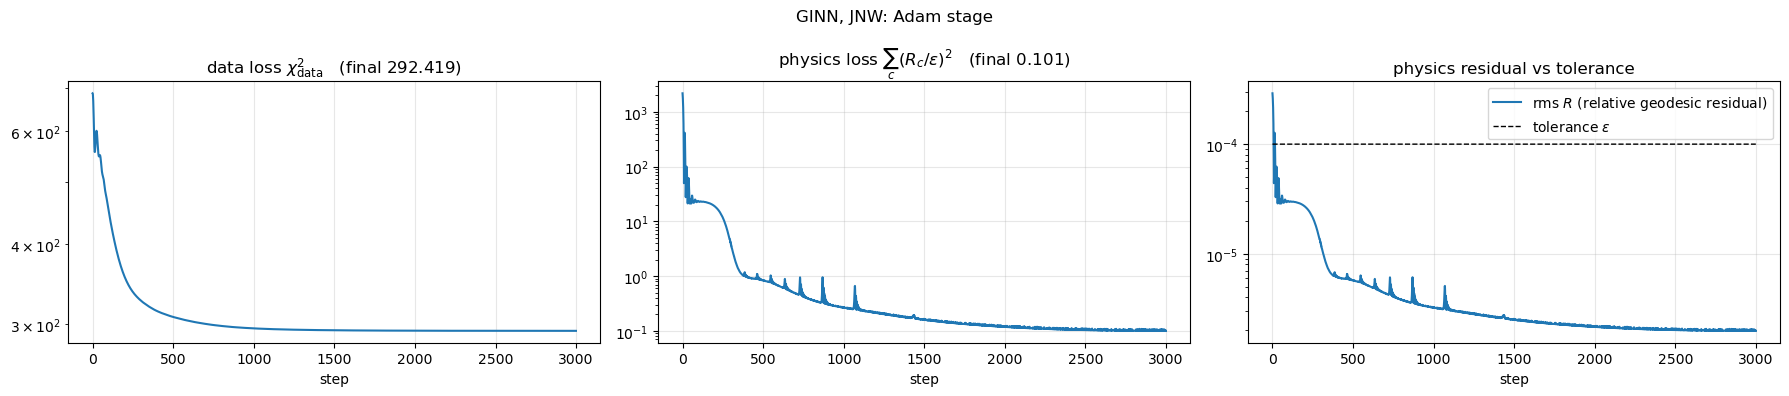

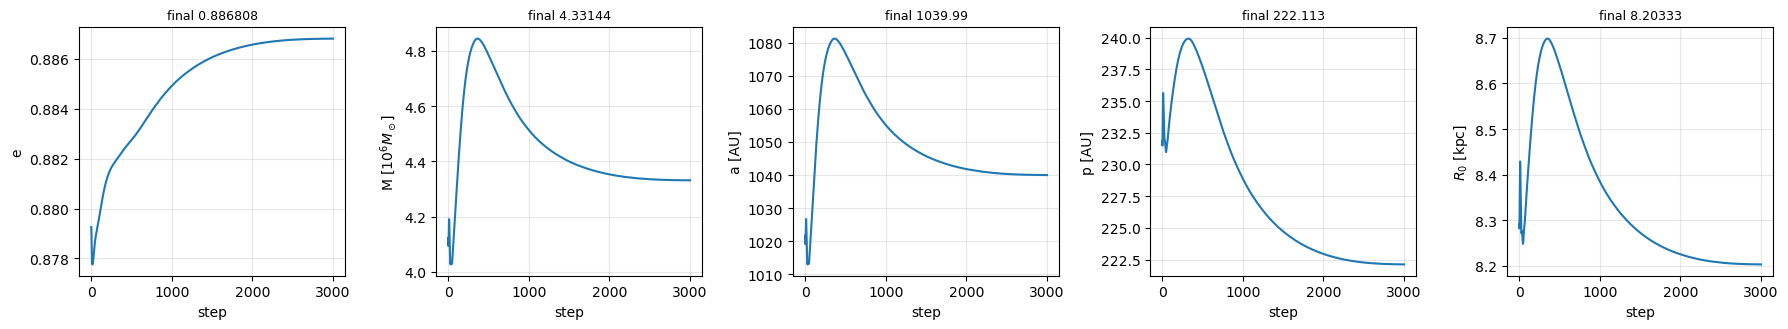

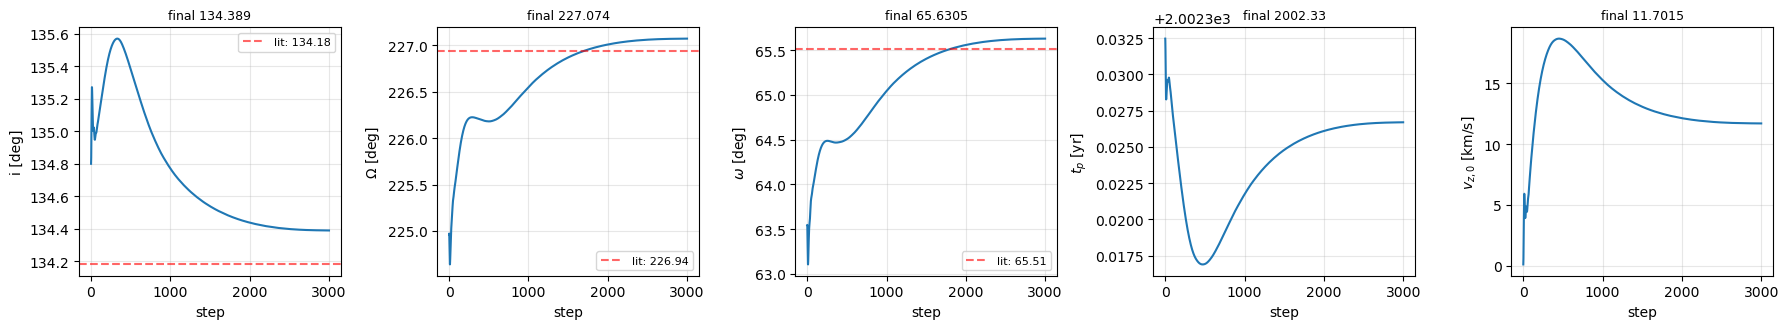

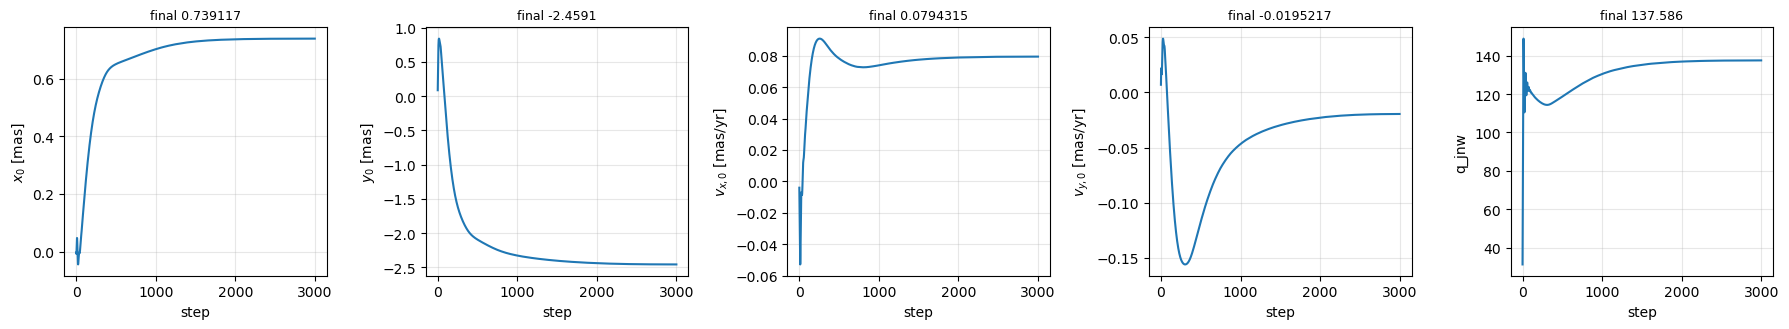

In [4]:
init = keplerian_prefit(data)
ginn, hist = fit(metric, data, init, timing='ginn', cfg=cfg, n_steps=N_STEPS_GINN,
                 hair_init=HAIR_INIT, fixed=tuple(set(HOLD) | set(FIXED)) if HOLD_HAIR_IN_ADAM else FIXED,
                 **MODEL, **TRAIN)
if HOLD_HAIR_IN_ADAM:
    for h in HOLD:
        ginn.fix(h, fixed=False)                 # release the hair for the polish
print('after Adam:', ginn.summary())
pl.plot_loss_history(hist, f'GINN, {metric.label}: Adam stage'); plt.show()
pl.plot_param_history(hist, lit=LIT); plt.show()

## Gauss–Newton polish

C:\Users\phys6\Downloads\GINN_final\GINN\notebooks\..\ginn\analysis.py:99: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  chi2=float((r ** 2).sum()), marginalized=use_nn, timing=timing,


GN 0: predicted chi2 gain    3.803   q_jnw = 137.59
GN 1: predicted chi2 gain    6.491   q_jnw = 91.84
GN 2: predicted chi2 gain    1.984   q_jnw = 66.84
GN 3: predicted chi2 gain    1.852   q_jnw = 54.34
GN 4: predicted chi2 gain    1.748   q_jnw = 41.84
GN 5: predicted chi2 gain    1.673   q_jnw = 29.34
GN 6: predicted chi2 gain    1.624   q_jnw = 16.84
GN 7: predicted chi2 gain    1.601   q_jnw = 4.3401
GN 8: predicted chi2 gain    1.607   q_jnw = -8.1599
GN 9: predicted chi2 gain    0.001   q_jnw = -1.9099

after polish: M = 4.2103e6 Msun | a = 1030.03 AU | e = 0.88725 | i = 134.087 | Om = 227.397 | om = 65.884 | t_p = 2002.3285 | D = 8.0781 kpc | vz0 = 10.24 km/s
   frame: x0 = +0.720 mas | y0 = -2.487 mas | vx0 = +0.1210 mas/yr | vy0 = +0.0120 mas/yr | q_jnw = -1.91


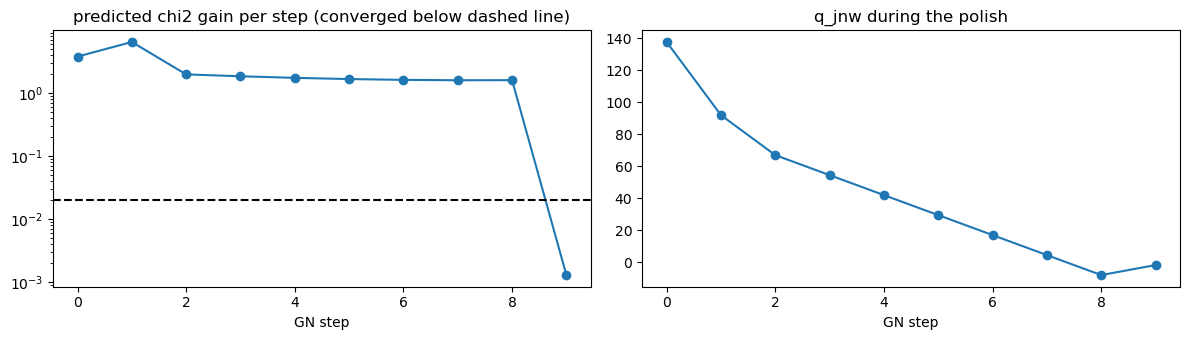

In [5]:
lap, gn_hist = an.gn_polish(ginn, data, cfg, **GN)
print('\nafter polish:', ginn.summary())
if HOLD:
    fig, ax = plt.subplots(1, 1 + len(HOLD), figsize=(6 * (1 + len(HOLD)), 3.5))
    ax[0].semilogy([max(h['chi2_gain'], 1e-4) for h in gn_hist], 'o-'); ax[0].axhline(GN['tol'], color='k', ls='--')
    ax[0].set_title('predicted chi2 gain per step (converged below dashed line)'); ax[0].set_xlabel('GN step')
    for a_, h in zip(ax[1:], HOLD):
        a_.plot([x[h] for x in gn_hist], 'o-'); a_.set_title(f'{h} during the polish'); a_.set_xlabel('GN step')
    plt.tight_layout(); plt.show()

## Results

In [18]:
post = an.posterior(ginn, data, cfg)
est = an.print_estimates(ginn, post)
S = an.sample_laplace(ginn, post, n=CORNER['n_samples'])
print()
for k in ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + FRAME:
    m_, lo_, hi_ = an.summarize(S)[k]; print(f"{k:6s} = {m_:.6g} +- {0.5 * (lo_ + hi_):.3g}")

q_jnw: d chi2 / d(q_jnw^2) = 8.329e-05  ->  sigma = 110   (slope measured at q_jnw = 10)
         q_jnw = -1.9099 +- 110   (0.0 sigma from GR)   (+ and - give the same metric)
[sample_laplace] 100.0% of samples inside the hair prior (the rest are rejected = Laplace x prior).

M      = 4.21032 +- 0.231
D      = 8.07779 +- 0.229
a      = 127.515 +- 1.4
e      = 0.88726 +- 0.00281
inc    = 134.086 +- 0.556
Omega  = 227.399 +- 0.732
omega  = 65.8845 +- 0.734
t0     = 2002.33 +- 0.00637
x0     = 0.718828 +- 0.222
y0     = -2.48862 +- 0.668
vx0    = 0.120825 +- 0.0459
vy0    = 0.012012 +- 0.0731
vz0    = 10.2317 +- 7.83


In [7]:
# save the best fit and its posterior (used by compare_orbits.ipynb and 00_validation_and_checks.ipynb)
import os
os.makedirs('results', exist_ok=True)
torch.save(dict(model=ginn, hair=est, post=post, cfg=cfg), f'results/{METRIC}.pt')
print(f'saved results/{METRIC}.pt')

saved results/jnw.pt


## Bayesian evidence
Laplace estimate of the evidence, from the same curvature as the error bars, relative to Schwarzschild (run 01_schwarzschild first). $\ln B>0$ favours this spacetime; the Occam term depends on the width of the hair prior.

In [8]:
ev = an.evidence(ginn, data, cfg, post)
r_ = torch.load(f'results/{METRIC}.pt', weights_only=False)
r_['evidence'] = ev
torch.save(r_, f'results/{METRIC}.pt')
ref_file = 'results/schwarzschild.pt'
ref = torch.load(ref_file, weights_only=False) if os.path.exists(ref_file) else {}
if METRIC == 'schwarzschild':
    print(f"chi2 = {ev['chi2']:.3f},   ln det Sigma = {ev['logdet_rest']:.3f}   (reference for all Bayes factors)")
elif 'evidence' in ref:
    an.print_bayes(metric.label, an.bayes_factor(ev, ref['evidence']))
else:
    print('run 01_schwarzschild.ipynb first: it provides the reference evidence')

model               dchi2  ln Occam  dln vol    ln B   evidence
JNW                 -0.00     -1.47    -0.00   -1.47   weak for Schwarzschild


In [9]:
# GRID_POST = [0.0, 40.0, 80.0, 120.0, 160.0, 200.0, 250.0, 300.0, 400.0]
# MODE = 'symmetric'
# H = HOLD[0]
# prof = an.gn_profile(ginn, data, cfg, H, GRID_POST, n_iter=4, n_retrain=GN['n_retrain'], lr_nn=GN['lr_nn'])
# prior = metric.hair_by_name(H).prior
# v = np.array(GRID_POST); mids = 0.5 * (v[1:] + v[:-1])
# lo0 = prior.lo if MODE == 'lower_edge' else 0.0
# edges = np.concatenate([[lo0], mids, [min(prior.hi, v[-1] + (v[-1] - mids[-1]))]])
# entries = [dict(model=r['model'], lap=r['lap'], chi2=r['chi2'], cell=(H, lo, hi))
#            for r, lo, hi in zip(prof['rows'], edges[:-1], edges[1:])]
# S, _ = an.mixture_posterior(entries, n=CORNER['n_samples'])
# if MODE == 'symmetric':
#     S[H] = S[H] * np.random.default_rng(1).choice([-1.0, 1.0], size=len(S[H]))
# print()
# for r, d in zip(prof['rows'], prof['dchi2']):
#     print(f"{H} = {r['value']:9.3f}   Delta chi2 = {d:8.3f}")
# if prof['dchi2'][-1] < 9:
#     print('WARNING: the last grid point is not strongly excluded (Delta chi2 < 9): extend the grid')
# lab = metric.hair_by_name(H).latex
# if MODE == 'lower_edge':
#     up_cred = float(np.percentile(S[H], 95))
#     print(f"\none-sided 95% upper limit (Delta chi2 = 2.71, prior-independent): {H} < {prof['upper_1sided95']:.2f}"
#           f"   (Lambda < {10**prof['upper_1sided95']:.2e} m^-2)")
#     print(f"95% credible upper bound with prior U({prior.lo:g}, {prior.hi:g}): {H} < {up_cred:.2f}  (prior-dependent)")
# else:
#     up_cred = float(np.percentile(np.abs(S[H]), 95))
#     print(f"\n95% bound: |{H}| < {up_cred:.3g}   (Delta chi2 = 2.71 on |{H}|: {prof['upper_1sided95']:.3g})")
#     print(f"posterior: {H} = {np.median(S[H]):.3g} +- {0.5*(np.percentile(S[H],84.135)-np.percentile(S[H],15.865)):.3g}")
# fig, ax = plt.subplots(1, 2, figsize=(14, 4))
# ax[0].hist(S[H], bins=150, density=True, color='#1f4e9c', histtype='stepfilled', alpha=0.6)
# for sgn in ([1] if MODE == 'lower_edge' else [-1, 1]):
#     ax[0].axvline(sgn * up_cred, color='k', ls=':', label='95% bound' if sgn == 1 else None)
# ax[0].set_xlabel(lab); ax[0].set_ylabel('posterior'); ax[0].legend()
# ax[1].plot(prof['values'], prof['dchi2'], 'o-', color='#1f4e9c'); ax[1].axhline(2.71, color='r', ls='--')
# ax[1].set_xlabel(lab if MODE == 'lower_edge' else '|' + H + '|'); ax[1].set_ylabel(r'$\Delta\chi^2$')
# ax[1].set_ylim(-0.3, min(40, max(10, prof['dchi2'].max()))); plt.tight_layout(); plt.show()

## Corner plots

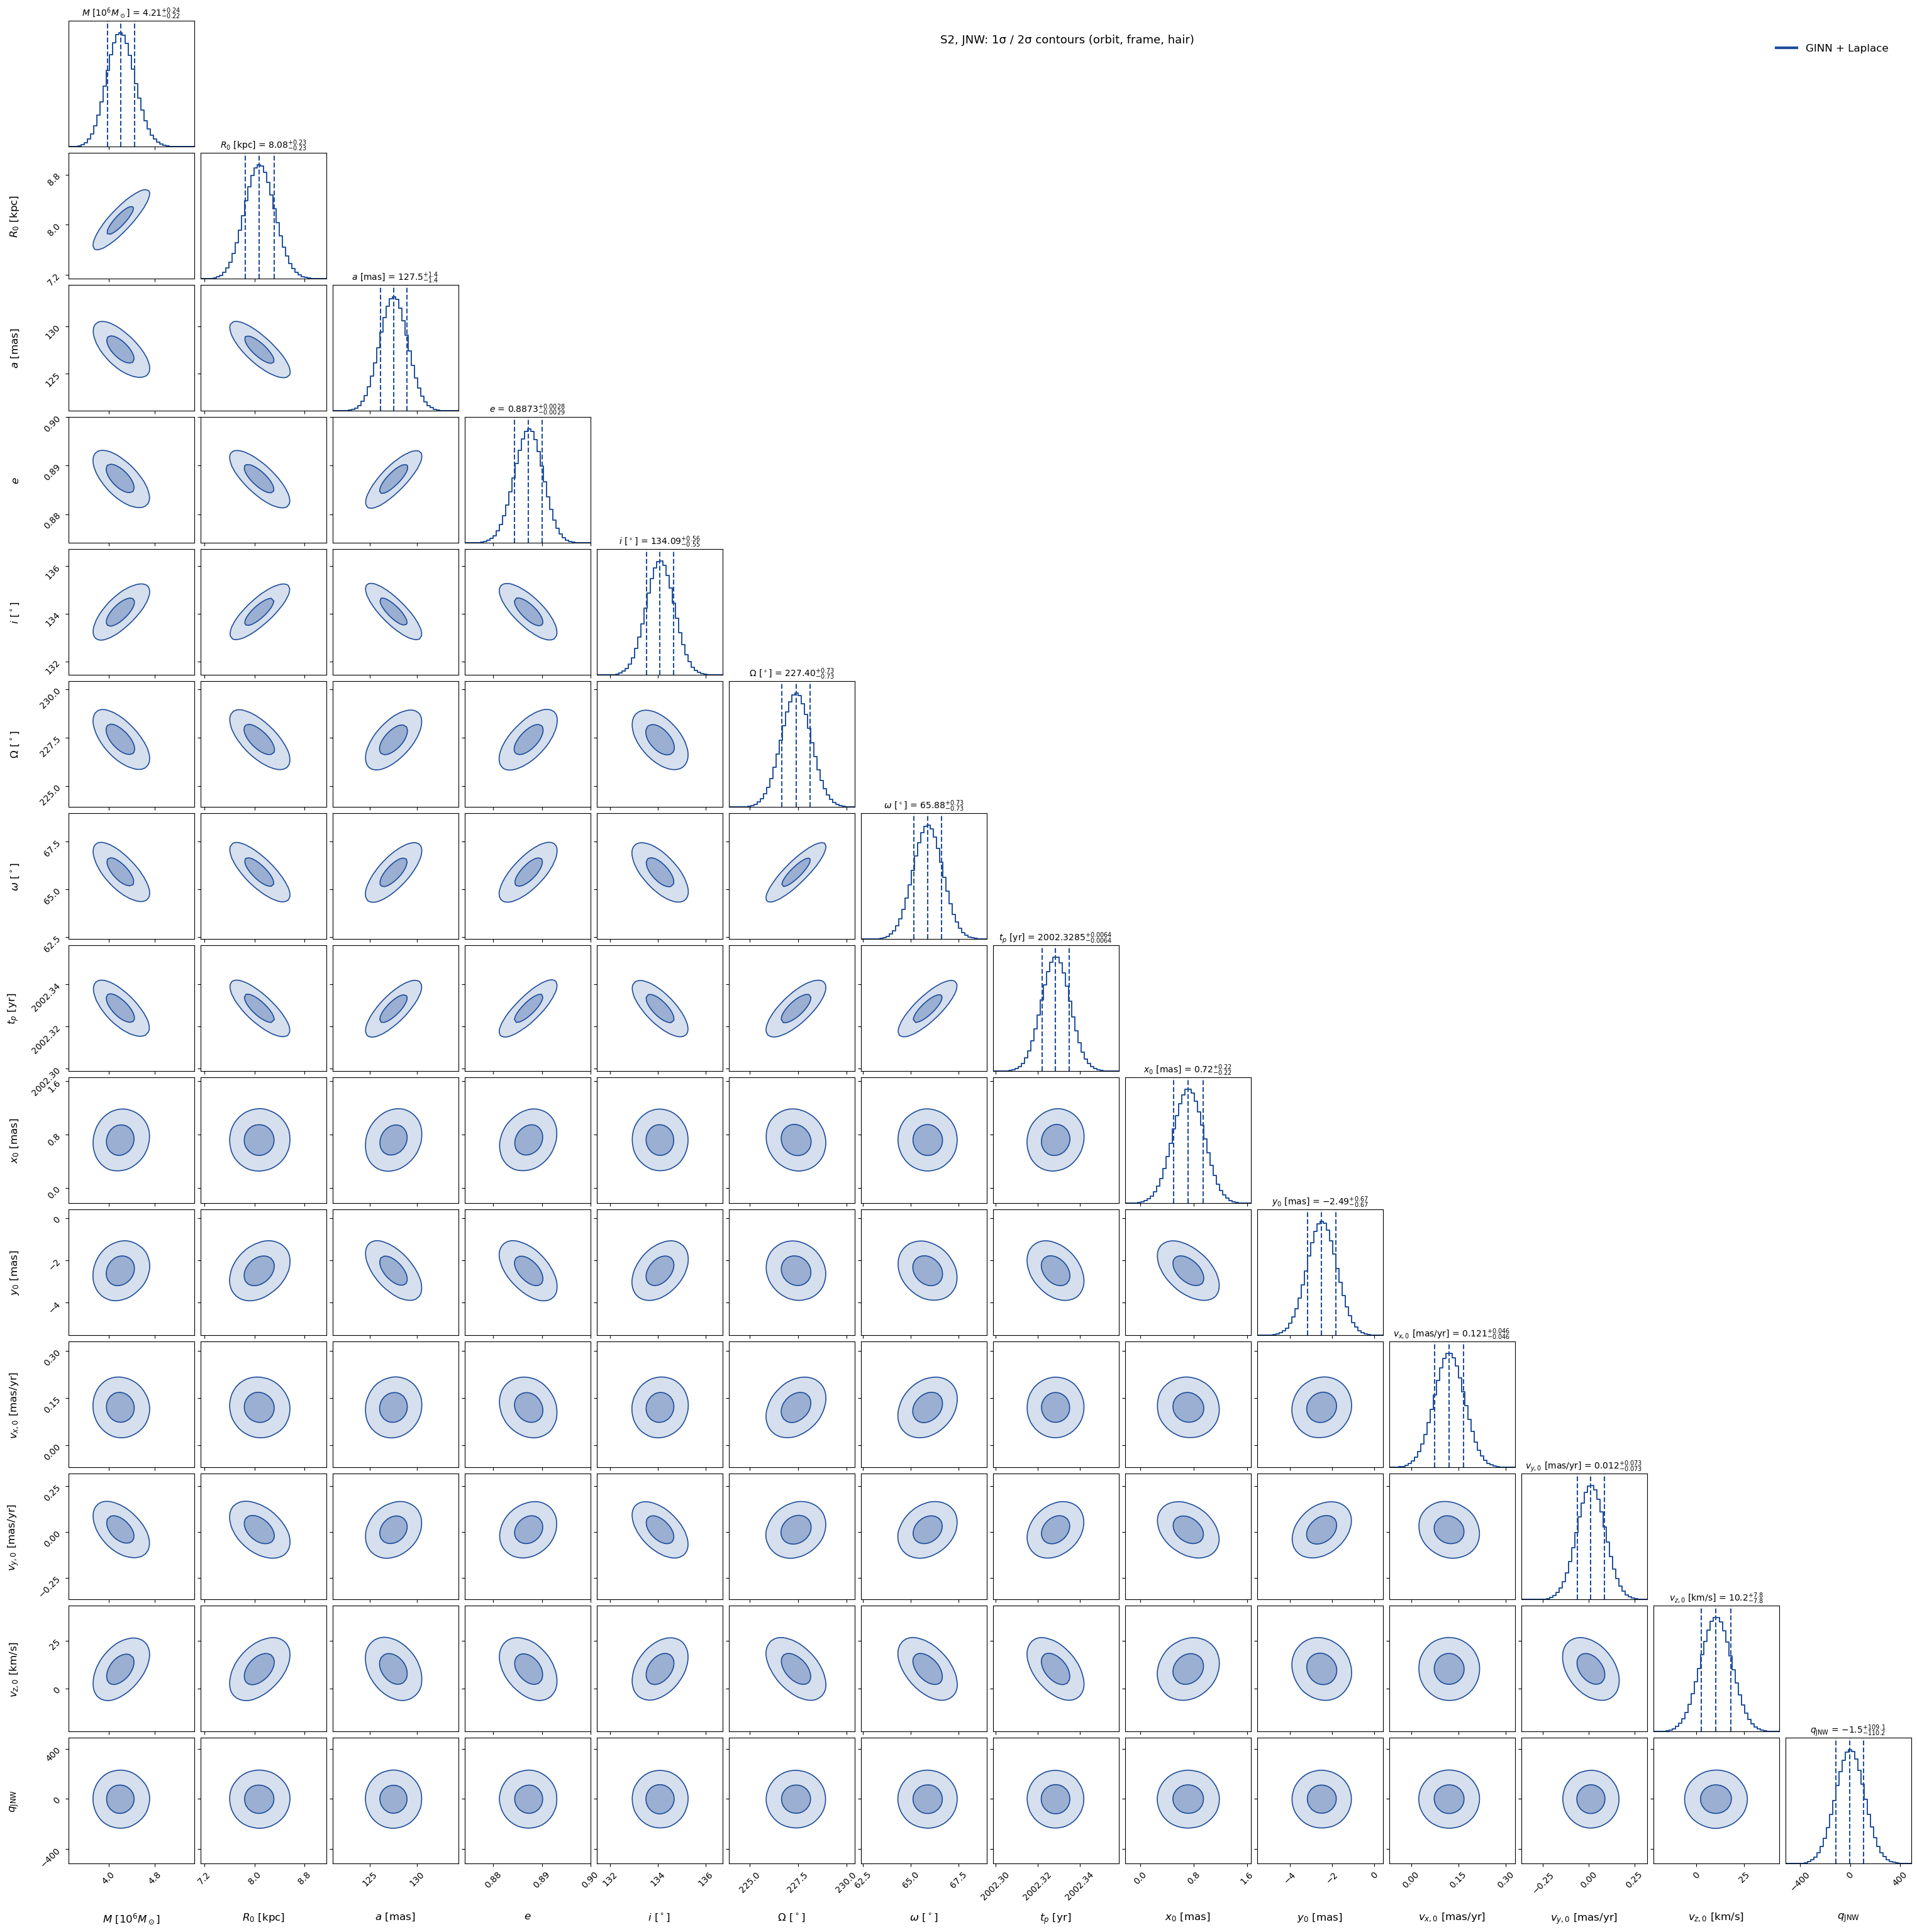

In [10]:
# one corner plot with ALL fitted parameters: orbit, hair and reference-frame offsets
keys = ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + FRAME + list(HOLD)   # ALL parameters, one plot
pl.corner_plot([S], an.labels_for(ginn), keys, names=['GINN + Laplace'],
               bins=CORNER['bins'], smooth=CORNER['smooth'],
               title=f'S2, {metric.label}: 1σ / 2σ contours (orbit, frame, hair)')
plt.savefig("corner_06_JNW.png")
plt.show()

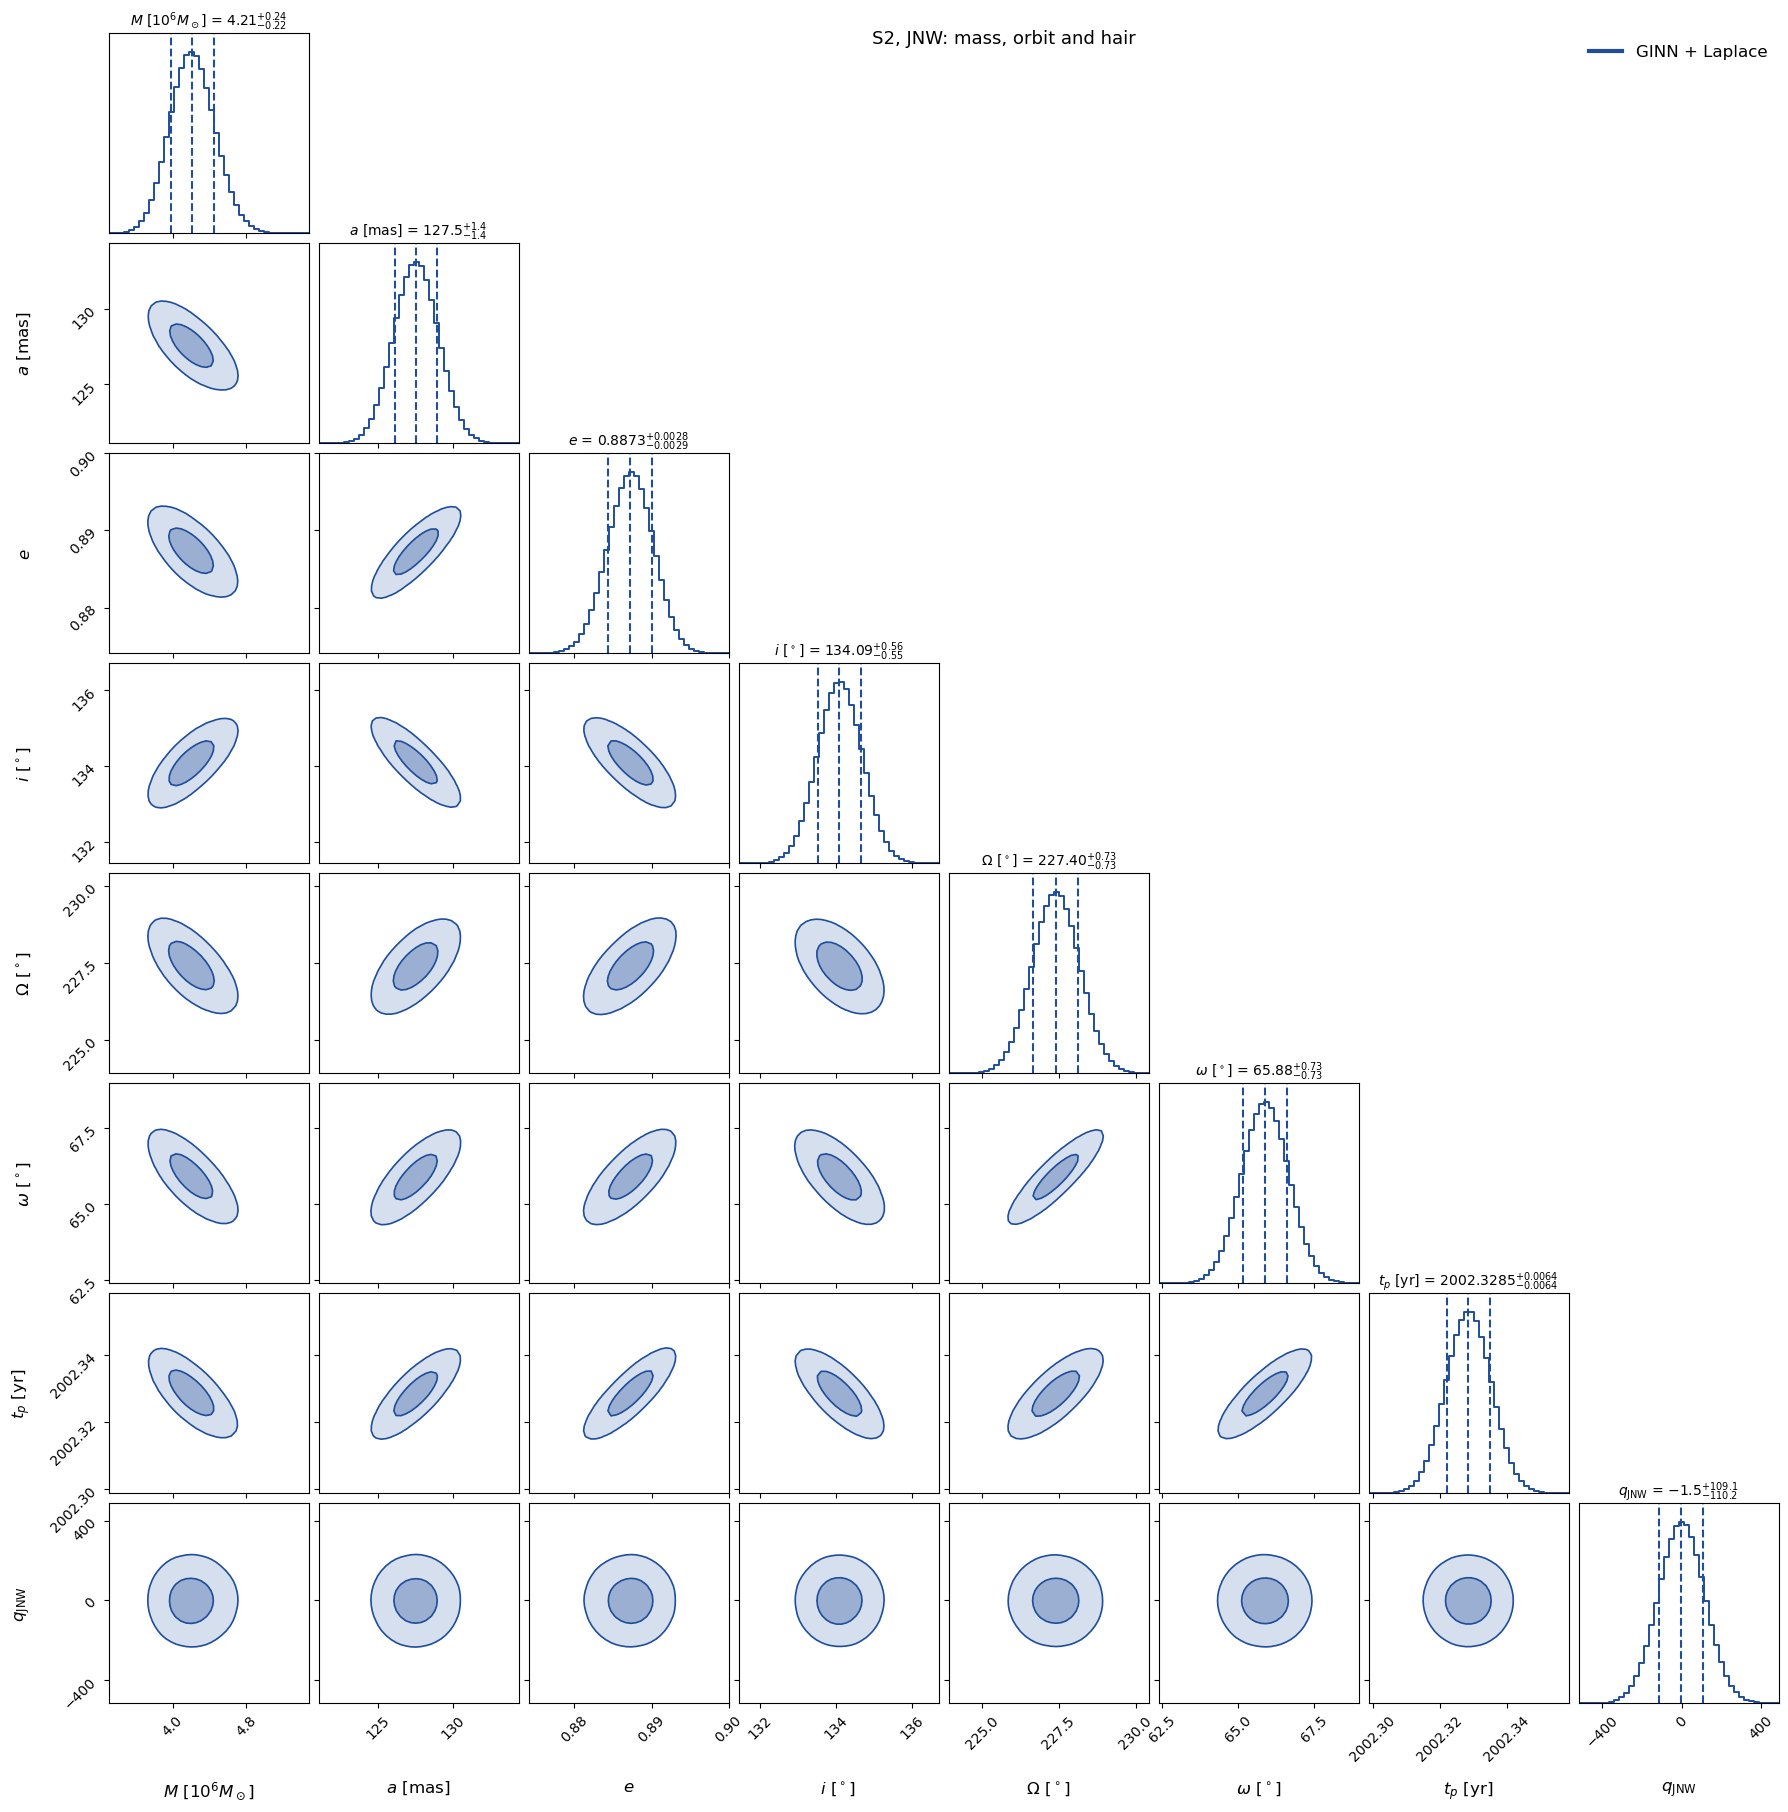

In [11]:
keys_red = ['M', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + list(HOLD)
pl.corner_plot([S], an.labels_for(ginn), keys_red, names=['GINN + Laplace'],
               bins=CORNER['bins'], smooth=CORNER['smooth'],
               title=f'S2, {metric.label}: mass, orbit and hair')
plt.savefig("small_corner_06_JNW.png")
plt.show()

In [12]:
#pl.plot_convergence(hist, S, gn_hist if HOLD else None, title=f'{metric.label}: convergence'); plt.show()

In [13]:
# keep the posterior samples for the summary plots in 09_compare_orbits
import os
res_file = f'results/{METRIC}.pt'
if os.path.exists(res_file):
    r_ = torch.load(res_file, weights_only=False)
    r_['samples'] = {k: np.asarray(v)[:20000] for k, v in S.items()}
    torch.save(r_, res_file)

## Beyond the quadratic approximation
The data residuals are expanded to second order in the physical parameters, with the network eliminated to the same order, so that $\chi^2$ contains terms up to fourth order. This posterior is sampled with MCMC and compared with the Gauss–Newton + Laplace result above: shifts of the mean in units of the Laplace $\sigma$, ratio of the widths, and skewness. The comparison with the exact geodesic solver is in 00_validation_and_checks.

The chain is shorter than 50 times the integrated autocorrelation time for 14 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 194;
tau: [337.52617729 279.59105406 305.85189211 285.87210348 292.00991899
 448.60676764 320.14878677 346.69846487 293.69345365 491.20306074
 468.76198199 493.14493599 466.76133136 611.67630731]


higher-order MCMC: 889 effective samples

             Gauss-Newton + Laplace |        dali: shift, sd ratio, skew
M               4.21663 +- 0.231     |      +0.02       0.959       +0.05 |
D               8.08106 +- 0.228     |      +0.02       0.951       -0.08 |
a               127.521 +- 1.39      |      -0.02       0.949       +0.21 |
e              0.887224 +- 0.0028    |      +0.13       0.969       +0.12 |
inc             134.086 +- 0.554     |      +0.03       0.949       -0.10 |
Omega           227.399 +- 0.732     |      -0.01       0.957       +0.03 |
omega            65.886 +- 0.732     |      +0.05       0.957       +0.05 |
t0              2002.33 +- 0.00635   |      +0.06       0.953       -0.03 |
q_jnw          -2.10985 +- 110       |      +0.02       0.815       -0.04 |

q_jnw: 95% interval  Gauss-Newton + Laplace [-216.6, +212.7]   dali [-172.5, +168.2]


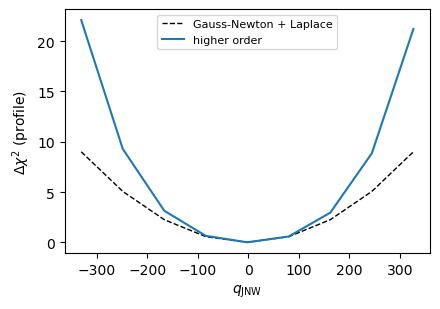

In [14]:
from ginn import higher_order as ho
HO_KEYS = ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + list(HOLD)
P = ho.Expansion(ginn, data, post, cfg).expand()
chain = ho.sample(P, 'dali', n=600_000)
st = {'laplace': ho.stats(ho.sample(P, 'laplace'), HO_KEYS), 'dali': ho.stats(chain, HO_KEYS)}
print(f"higher-order MCMC: {chain['n_eff']:.0f} effective samples\n")
ho.print_compare(st, HO_KEYS, names=('dali',), hair=list(HOLD))
names = list(HOLD) or ['logM']
fig, axs = plt.subplots(1, len(names), figsize=(4.5 * len(names), 3.2), squeeze=False)
for a_, nm in zip(axs[0], names):
    pr = ho.profile(P, nm)
    if nm == 'logM':
        ho.plot_profile(a_, pr, label=r'$M\ [10^6 M_\odot]$', transform=lambda x: np.exp(x) / 1e6)
    else:
        ho.plot_profile(a_, pr, label=an.labels_for(ginn)[nm])
axs[0][0].legend(fontsize=8); plt.tight_layout(); plt.show()
r_ = torch.load(f'results/{METRIC}.pt', weights_only=False)
r_['higher_order'] = st
torch.save(r_, f'results/{METRIC}.pt')

## Some checks

chi2 (N_data = 334)                     RA      Dec      RV     total
  GINN                                         140.76   137.68   11.56   290.002
  without network                              140.78   137.79   11.53   290.097
  geodesic timing numerical                    140.76   137.68   11.56   290.002
we compare chi-squared improvement due to GINN and exact numerical correction - should be more or less equal


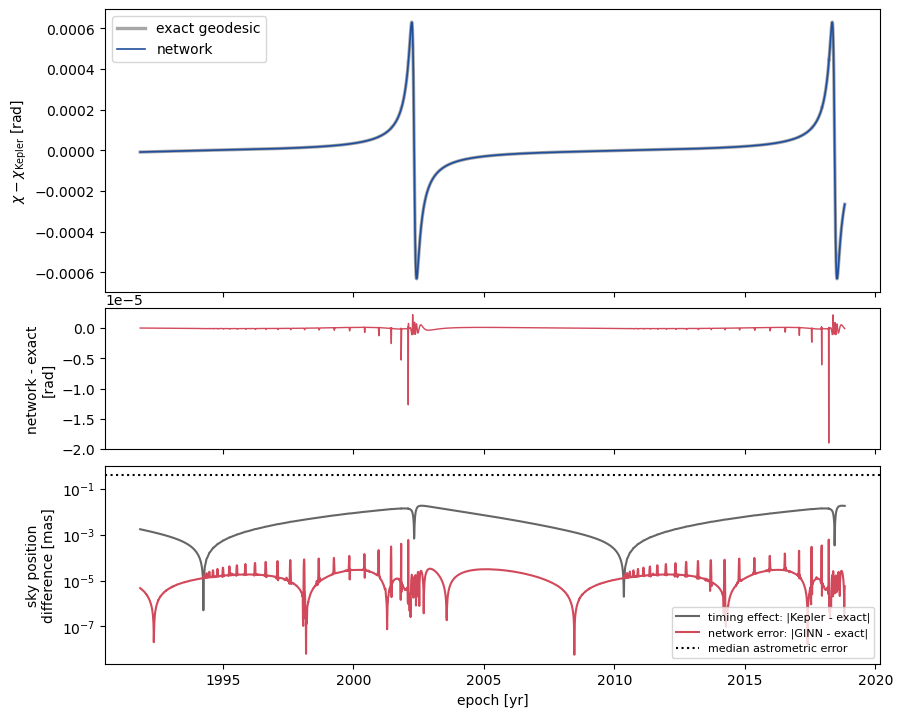

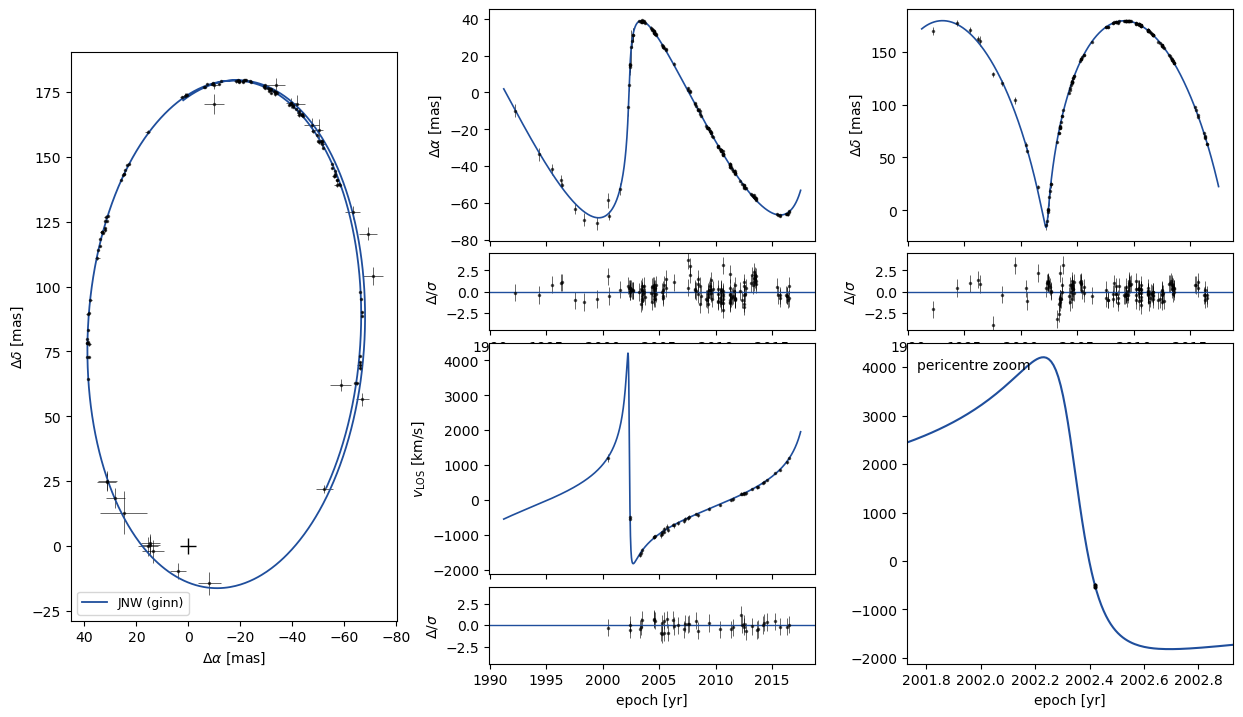

In [15]:
rep = an.nn_role_report(ginn, data, cfg, lap=post)
pl.plot_timing(rep['timing_curves'], data); plt.show()
pl.plot_fit(ginn, data); plt.show()

In [16]:
# exact, _ = fit(metric, data, init, timing='exact', cfg=cfg, n_steps=N_STEPS_EXACT,
#                hair_init=HAIR_INIT, fixed=FIXED, **TRAIN)
# lap_ex = an.laplace(exact, data, cfg)
# print('exact solver:', exact.summary())
# print('exact solver hair:', an.hair_estimates(exact, lap_ex))

## Multi-start



start -50: q_jnw: Adam -131.77 -> polish -2.0543 +- 110  | M = 4.2113, R0 = 8.0788 | chi2 Adam 292.10 -> 290.00 (10 GN steps)
start +1: q_jnw: Adam +111.71 -> polish +0.48899 +- 110  | M = 4.2067, R0 = 8.0757 | chi2 Adam 291.22 -> 290.00 (10 GN steps)
start +50: q_jnw: Adam +131.77 -> polish +2.0543 +- 110  | M = 4.2113, R0 = 8.0788 | chi2 Adam 292.10 -> 290.00 (10 GN steps)

         q_jnw: spread across starts = 0.01 sigma  ->  CONSISTENT
             M: spread across starts = 0.02 sigma  ->  CONSISTENT
            R0: spread across starts = 0.01 sigma  ->  CONSISTENT


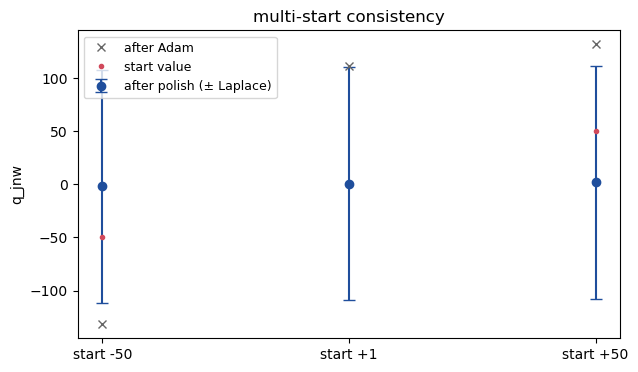

In [19]:
RUN_MULTISTART = True
MULTI_STARTS = [-50.0, 1.0, 50.0]
ms_rows = []
if RUN_MULTISTART:
    for s0 in MULTI_STARTS:
        if HOLD:
            hi, seed = {**HAIR_INIT, HOLD[0]: s0}, 0
        else:
            hi, seed = HAIR_INIT, int(s0)
        m_, h_ = fit(metric, data, init, timing='ginn', cfg=cfg, n_steps=N_STEPS_GINN, hair_init=hi,
                     fixed=FIXED, seed=seed, progress=False, **MODEL, **TRAIN)
        adam = {k: float(m_.physical()['par'][k]) for k in HOLD}
        chi2_adam = an.chi2_parts(m_, data)['total']
        lap_, gh_ = an.gn_polish(m_, data, cfg, verbose=False, **GN)
        post_ = an.posterior(m_, data, cfg, verbose=False)
        S_ = an.sample_laplace(m_, post_, n=20000, verbose=False)
        row = dict(start=s0, adam=adam, chi2_adam=chi2_adam, est=an.hair_estimates(m_, post_),
                   chi2=an.chi2_parts(m_, data)['total'], steps=len(gh_),
                   M=an.summarize(S_)['M'], D=an.summarize(S_)['D'])
        ms_rows.append(row)
        txt = '  '.join(f"{k}: Adam {row['adam'][k]:+.5g} -> polish {row['est'][k][0]:+.5g} +- {row['est'][k][1]:.3g}" for k in HOLD)
        print(f"start {s0:+g}: {txt}  | M = {row['M'][0]:.4f}, R0 = {row['D'][0]:.4f} | chi2 Adam {chi2_adam:.2f} -> {row['chi2']:.2f} ({row['steps']} GN steps)")
    def spread(vals, sig):
        return (max(vals) - min(vals)) / sig
    sym = lambda k, v: abs(v) if k in an.SQUARED_HAIR else v
    checks = [(k, [sym(k, r['est'][k][0]) for r in ms_rows], np.mean([r['est'][k][1] for r in ms_rows])) for k in HOLD]
    checks += [('M', [r['M'][0] for r in ms_rows], np.mean([0.5 * (r['M'][1] + r['M'][2]) for r in ms_rows])),
               ('R0', [r['D'][0] for r in ms_rows], np.mean([0.5 * (r['D'][1] + r['D'][2]) for r in ms_rows]))]
    print()
    for k, vals, sig in checks:
        sp = spread(vals, sig)
        print(f"{k:>14s}: spread across starts = {sp:.2f} sigma  ->  " +
              ('CONSISTENT' if sp < 0.2 else 'NOT CONSISTENT (increase N_STEPS_GINN or GN n_iter)'))
    if HOLD:
        k = HOLD[0]
        fig, ax = plt.subplots(figsize=(7, 4))
        xs = np.arange(len(ms_rows))
        ax.errorbar(xs, [r['est'][k][0] for r in ms_rows], [r['est'][k][1] for r in ms_rows], fmt='o',
                    color='#1f4e9c', capsize=4, label='after polish (± Laplace)')
        ax.plot(xs, [r['adam'][k] for r in ms_rows], 'x', color='0.4', label='after Adam')
        ax.plot(xs, [r['start'] for r in ms_rows], '.', color='#d1495b', label='start value')
        ax.set_xticks(xs); ax.set_xticklabels([f"start {r['start']:+g}" for r in ms_rows])
        ax.set_ylabel(k); ax.legend(fontsize=9); ax.set_title('multi-start consistency'); plt.show()